In [1]:
from gas.gas_circuit import GAS_dicke, bin_to_int

In [2]:
import numpy as np 
import json
import os 
import h5py

from qiskit_aer import StatevectorSimulator

from symmer.operators.base import PauliwordOp, QuantumState

In [3]:
import h5py

with h5py.File("LiH_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["SCF_nelec"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["h1e_MO"][()].shape[0]
    energy_soln = infile["SCF_e_tot"][()]


print("LOADED")

LOADED


In [4]:
### write QUBO problem!

from sympy import var
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

168.0*x0*x1 + 36.0*x0*x10 + 36.0*x0*x11 + 36.0*x0*x2 + 40.0*x0*x3 + 36.0*x0*x4 + 40.0*x0*x5 + 40.0*x0*x6 + 40.0*x0*x7 + 40.0*x0*x8 + 40.0*x0*x9 - 478.0*x0 + 36.0*x1*x10 + 36.0*x1*x11 + 40.0*x1*x2 + 36.0*x1*x3 + 40.0*x1*x4 + 36.0*x1*x5 + 40.0*x1*x6 + 40.0*x1*x7 + 40.0*x1*x8 + 40.0*x1*x9 - 478.0*x1 + 44.0*x10*x11 + 32.0*x10*x2 + 44.0*x10*x3 + 20.0*x10*x4 + 24.0*x10*x5 + 24.0*x10*x6 + 28.0*x10*x7 + 24.0*x10*x8 + 28.0*x10*x9 - 90.0*x10 + 44.0*x11*x2 + 32.0*x11*x3 + 24.0*x11*x4 + 20.0*x11*x5 + 28.0*x11*x6 + 24.0*x11*x7 + 28.0*x11*x8 + 24.0*x11*x9 - 90.0*x11 + 48.0*x2*x3 + 20.0*x2*x4 + 24.0*x2*x5 + 24.0*x2*x6 + 28.0*x2*x7 + 24.0*x2*x8 + 28.0*x2*x9 - 150.0*x2 + 24.0*x3*x4 + 20.0*x3*x5 + 28.0*x3*x6 + 24.0*x3*x7 + 28.0*x3*x8 + 24.0*x3*x9 - 150.0*x3 + 32.0*x4*x5 + 24.0*x4*x6 + 28.0*x4*x7 + 24.0*x4*x8 + 28.0*x4*x9 - 110.0*x4 + 28.0*x5*x6 + 24.0*x5*x7 + 28.0*x5*x8 + 24.0*x5*x9 - 110.0*x5 + 32.0*x6*x7 + 28.0*x6*x8 + 28.0*x6*x9 - 116.0*x6 + 28.0*x7*x8 + 28.0*x7*x9 - 116.0*x7 + 32.0*x8*x9 - 116.0*x8 

In [5]:
from itertools import combinations
def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigvals_counter = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        
        eigvals_counter[evaluated] = eigvals_counter.get(evaluated, 0) + 1

eigvals_counter, min(eigvals_counter.keys())

({-888: 1,
  -872: 2,
  -870: 4,
  -836: 2,
  -680: 2,
  -678: 4,
  -632: 2,
  -662: 8,
  -628: 2,
  -660: 6,
  -626: 4,
  -824: 1,
  -830: 4,
  -816: 2,
  -656: 6,
  -636: 2,
  -614: 4,
  -600: 8,
  -620: 6,
  -606: 4,
  -828: 2,
  -832: 2,
  -814: 4,
  -658: 4,
  -630: 4,
  -616: 4,
  -602: 8,
  -618: 4,
  -604: 4,
  -780: 1,
  -624: 2,
  -622: 4,
  -576: 2,
  -568: 2,
  -566: 4,
  -352: 3,
  -354: 4,
  -308: 2,
  -330: 8,
  -296: 6,
  -332: 6,
  -298: 8,
  -348: 2,
  -302: 4,
  -336: 4,
  -292: 4,
  -236: 4,
  -306: 4,
  -252: 2,
  -300: 2,
  -246: 4,
  -284: 2,
  -288: 3,
  -270: 8,
  -290: 4,
  -272: 6,
  -276: 4,
  -238: 4,
  -232: 2},
 -888)

In [6]:
## lowest 10 eigenvalues
sorted(eigvals_counter.keys())[:10]

[-888, -872, -870, -836, -832, -830, -828, -824, -816, -814]

In [7]:
nq_qubo = f_op.n_qubits
maxval_qubo = np.abs(list(linear_rounded.values())).sum() + np.abs(list(quad_rounded.values())).sum()

print(f"number of QUBO qubits: {nq_qubo}")
print(f"maximum QUBO value possible: {maxval_qubo}")

number of QUBO qubits: 12
maximum QUBO value possible: 4308.0


In [8]:
nq_fx = int(np.ceil(np.log2(maxval_qubo))) + 1 # add one for negative values
print(f"maximum of f(x) qubits: {nq_fx}")

maximum of f(x) qubits: 14


In [9]:
total_nq = nq_qubo + nq_fx
total_nq

26

In [10]:
## get binary value for all 1s state (max value) for na and nb counts!
na_target = int(n_elec[0])
nb_target = int(n_elec[1])


In [12]:
from qiskit import transpile, QuantumCircuit
from gas.dicke import dicke_state

alph_dicke = dicke_state(nq_qubo//2, na_target).to_gate()
beta_dicke = dicke_state(nq_qubo//2, nb_target).to_gate()

full_dicke = QuantumCircuit(nq_qubo)
full_dicke.append(alph_dicke, [2*qi for qi in range(nq_qubo//2)])
full_dicke.append(beta_dicke, [2*qi+1 for qi in range(nq_qubo//2)])

full_dicke = transpile(full_dicke, basis_gates=['id', 'ry', 'rx', 'cx'], optimization_level=1, seed_transpiler=1) 

In [13]:
# Check output of Dicke circuit
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_dicke.decompose().decompose())

statevec_dicke = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec_dicke[np.abs(statevec_dicke)<1e-15] = 0 # zero out vanishingly small terms!
psi_dicke = QuantumState.from_array(statevec_dicke)
psi_dicke

 0.067+0.000j |000000001111> +
 0.067+0.000j |000000011011> +
 0.067+0.000j |000000011110> +
 0.067+0.000j |000000100111> +
 0.067+0.000j |000000101101> +
 0.067+0.000j |000000110011> +
 0.067+0.000j |000000110110> +
 0.067+0.000j |000000111001> +
 0.067+0.000j |000000111100> +
 0.067+0.000j |000001001011> +
 0.067+0.000j |000001001110> +
 0.067+0.000j |000001011010> +
 0.067+0.000j |000001100011> +
 0.067+0.000j |000001100110> +
 0.067+0.000j |000001101001> +
 0.067+0.000j |000001101100> +
 0.067+0.000j |000001110010> +
 0.067+0.000j |000001111000> +
 0.067+0.000j |000010000111> +
 0.067+0.000j |000010001101> +
 0.067+0.000j |000010010011> +
 0.067+0.000j |000010010110> +
 0.067+0.000j |000010011001> +
 0.067+0.000j |000010011100> +
 0.067+0.000j |000010100101> +
 0.067+0.000j |000010110001> +
 0.067+0.000j |000010110100> +
 0.067+0.000j |000011000011> +
 0.067+0.000j |000011000110> +
 0.067+0.000j |000011001001> +
 0.067+0.000j |000011001100> +
 0.067+0.000j |000011010010> +
 0.067+0

In [14]:
gas_obj_dicke = GAS_dicke( nq_qubo, 
                        nq_fx,
                        linear_rounded,
                        quad_rounded,
                        full_dicke)

In [15]:
## do 1 repeat
## filter below y=-850 (should boost 7 eigenstates)


n_repeats = 1
full_circuit2 = gas_obj_dicke.build_circuit(850,
                                            n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out2 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out2

 0.192+0.000j |000100001011> +
 0.192+0.000j |001000000111> +
 0.192+0.000j |000010000111> +
 0.192+0.000j |000001001011> +
 0.192+0.000j |000000100111> +
 0.192+0.000j |000000011011> +
 0.192+0.000j |000000001111> +
 0.058+0.000j |000000111100> +
 0.058+0.000j |000001101100> +
 0.058+0.000j |000010011100> +
 0.058+0.000j |000011001100> +
 0.058+0.000j |000001111000> +
 0.058+0.000j |000011100100> +
 0.058+0.000j |000010110100> +
 0.058+0.000j |000011011000> +
 0.058+0.000j |100000011100> +
 0.058+0.000j |000000011110> +
 0.058+0.000j |000000111001> +
 0.058+0.000j |000011110000> +
 0.058+0.000j |000000101101> +
 0.058+0.000j |000100101100> +
 0.058+0.000j |001000011100> +
 0.058+0.000j |000010001101> +
 0.058+0.000j |000110001100> +
 0.058+0.000j |000000110110> +
 0.058+0.000j |000001001110> +
 0.058+0.000j |010000101100> +
 0.058+0.000j |100001001100> +
 0.058+0.000j |000100111000> +
 0.058+0.000j |001001001100> +
 0.058+0.000j |001000110100> +
 0.058+0.000j |000010011001> +
 0.058+0

In [16]:
full_circuit2.num_qubits

26

In [32]:
## let us do more repeats to see boost
## filter below y=-850 (should boost 7 eigenstates)


n_repeats = 3 #<--- increased
full_circuit2 = gas_obj_dicke.build_circuit(850,
                                            n_repeats)


# Simulator 
simulator_aerlegacy = StatevectorSimulator()
result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
psi_out2 = QuantumState.from_array(statevec2)


psi_out3 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                       np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()

psi_out3

 0.358+0.000j |001000000111> +
 0.358+0.000j |000100001011> +
 0.358+0.000j |000010000111> +
 0.358+0.000j |000001001011> +
 0.358+0.000j |000000100111> +
 0.358+0.000j |000000011011> +
 0.358+0.000j |000000001111> +
 0.022+0.000j |000011001100> +
 0.022+0.000j |000001101100> +
 0.022+0.000j |000000111100> +
 0.022+0.000j |000010011100> +
 0.022+0.000j |000001111000> +
 0.022+0.000j |000000011110> +
 0.022+0.000j |010000101100> +
 0.022+0.000j |000011011000> +
 0.022+0.000j |100000011100> +
 0.022+0.000j |000011100100> +
 0.022+0.000j |000010110100> +
 0.022+0.000j |000001001110> +
 0.022+0.000j |000010001101> +
 0.022+0.000j |000100101100> +
 0.022+0.000j |001000011100> +
 0.022+0.000j |000011110000> +
 0.022+0.000j |000110001100> +
 0.022+0.000j |100001001100> +
 0.022+0.000j |000000101101> +
 0.022+0.000j |010010001100> +
 0.022+0.000j |000100111000> +
 0.022+0.000j |001001001100> +
 0.022+0.000j |000010100101> +
 0.022+0.000j |000010011001> +
 0.022+0.000j |000000110110> +
 0.022+0

In [36]:
## Let us loop over different numbers of repeats for this circuit
## Here we are thresholding at -880 (so that only g.s.) should be amplified.

repeat_list_dicke = np.arange(1,12)
output_states_list_dicke = []
for rep in repeat_list_dicke:
    print(f"L={rep} start")
    full_circuit2 = gas_obj_dicke.build_circuit(880,
                                                 rep)


    # Simulator 
    simulator_aerlegacy = StatevectorSimulator()
    result_aerlegacy = simulator_aerlegacy.run(full_circuit2.decompose().decompose())

    statevec2 = result_aerlegacy.result().get_statevector().data.reshape([-1, 1])
    statevec2[np.abs(statevec2)<1e-15] = 0 # zero out vanishingly small terms!
    psi_out2 = QuantumState.from_array(statevec2)

    ## slice out only QUBO register qubits
    psi_out4 = QuantumState(psi_out2.state_matrix[:, -f_op.n_qubits:],
                        np.abs(psi_out2.state_op.coeff_vec)).cleanup().normalize.sort()
    
    output_states_list_dicke.append(psi_out4)
    print(f"L={rep} finished")

L=1 start
L=1 finished
L=2 start
L=2 finished
L=3 start
L=3 finished
L=4 start
L=4 finished
L=5 start
L=5 finished
L=6 start
L=6 finished
L=7 start
L=7 finished
L=8 start
L=8 finished
L=9 start
L=9 finished
L=10 start
L=10 finished
L=11 start
L=11 finished


Text(0, 0.5, 'Probability')

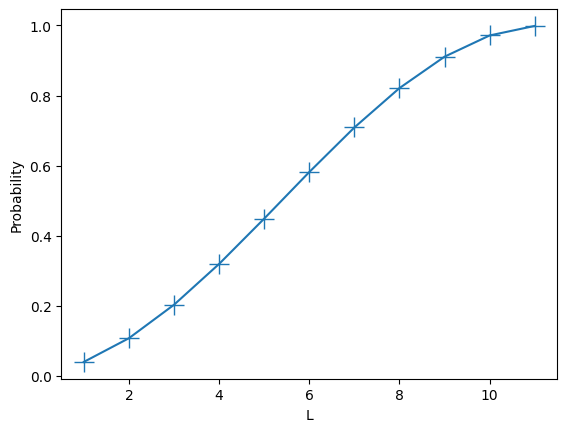

In [38]:
import matplotlib.pyplot as plt
          
largest_amp_list_dicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in output_states_list_dicke]
largest_bitstring_dicke = [psi[0] for psi in output_states_list_dicke]

plt.plot(repeat_list_dicke, largest_amp_list_dicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel("Probability")

In [39]:
largest_bitstring_dicke

[ 0.199+0.000j |000000001111>,
  0.327+0.000j |000000001111>,
  0.450+0.000j |000000001111>,
  0.565+0.000j |000000001111>,
  0.670+0.000j |000000001111>,
  0.763+0.000j |000000001111>,
  0.842+0.000j |000000001111>,
  0.906+0.000j |000000001111>,
  0.954+0.000j |000000001111>,
  0.986+0.000j |000000001111>,
  0.999+0.000j |000000001111>]

In [40]:
## save output states!

with h5py.File("LiH_output.h5", "w") as outf:
    for idx, psi in enumerate(output_states_list_dicke):
        outf.create_dataset(f"psi_{idx}_state_matrix", data=psi.state_matrix)
        outf.create_dataset(f"psi_{idx}_coeff_vec", data=psi.state_op.coeff_vec)

In [63]:
state = QuantumState(largest_bitstring_dicke[-1].state_matrix[0,::-1]) # need to reverse as qiskit encocdes left to right

final_energy =f_op.expval(state)

print(f"The calculated energy is: {final_energy}, for the bitstring with probability: {np.abs(largest_bitstring_dicke[-1].state_op.coeff_vec)**2} to be measured")

The calculated energy is: (-7.8633576215351075+0j), for the bitstring with probability: [0.99868108] to be measured


In [66]:
print(f"error with the true answer is: {energy_soln-final_energy}")

error with the true answer is: (-5.329070518200751e-15+0j)
